# Arctic Bird Album: A Year of Bird Movement

Issue #18. Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

This album turns one year of Arctic bird movement into music. The notebook answers four questions about the data behind EIC page [4877](https://svs.gsfc.nasa.gov/4877/):

1. **What is it?** Animal tracking data from the Arctic Animal Movement Archive (AAMA) in Movebank.
2. **How much is there?** Studies, species, individuals, locations and years.
3. **How is it distributed?** Over the years, the months and the latitudes.
4. **What does it say?** EIC's message, and how each species moves through one year.

It ends with the four bird species that travel the farthest in a year.

Run with `npm run notebook`. Downloads go to `data/arctic_bird/raw/` (local only). No login is needed. The Movebank download is rate limited and takes about an hour on the first run; reruns read the local files.

In [1]:
import html
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/arctic_bird/raw")
for sub in ("api", "movebank"):
    (RAW / sub).mkdir(parents=True, exist_ok=True)

SVS_ID = 4877
EIC_GALLERY = 40467
MOVEBANK = "https://www.movebank.org/movebank/service/public/json"
AAMA_URL = "https://www.movebank.org/cms/movebank-content/arctic-animal-movement-archive"
ZENODO_URL = "https://zenodo.org/record/4122502"
PAPER_DOI = "https://doi.org/10.1126/science.abb7080"


def download(name, url, session=None):
    """Download url into data/arctic_bird/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", " ", text or "")).replace("  ", " ").strip()


def source_note(ax, text, y=-0.18):
    ax.annotate(text, xy=(0, y), xycoords="axes fraction", fontsize=8, color="gray")


CREDIT = "Source: Arctic Animal Movement Archive, Movebank (public studies). Davidson et al. 2020, Science."

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API and the Movebank API, so they stay correct if either changes.

### 1.1 Where the visualization sits in the EIC gallery

In [2]:
def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
trails = {" › ".join(step for _, step in trail) for trail in paths.get(SVS_ID, [])}
# 4877 is not listed in a gallery itself: it is a source of an EIC video page
videos = {i: t for i, t in paths.items() if any(trail[0][1].startswith("EIC Videos") for trail in t)}
for page_id, page_trails in videos.items():
    if any(src["id"] == SVS_ID for src in svs_page(page_id).get("sources") or []):
        for trail in page_trails:
            trails.add(" › ".join(step for _, step in trail) + f" › sources → [{SVS_ID}](https://svs.gsfc.nasa.gov/{SVS_ID}/)")
display(Markdown("\n".join([
    "| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |",
    "| --- | --- |",
    f"| [{SVS_ID}](https://svs.gsfc.nasa.gov/{SVS_ID}/) | {'<br>'.join(sorted(trails)) or 'not found'} |",
])))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [4877](https://svs.gsfc.nasa.gov/4877/) | EIC Videos → [NASA + The Smithsonian: Biodiversity](https://svs.gsfc.nasa.gov/14700/) › sources → [4877](https://svs.gsfc.nasa.gov/4877/) |

### 1.2 What the page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of the SVS page, as published. None of them has a link.
- **Downloaded here** is what this notebook actually reads.

In [3]:
page = svs_page(SVS_ID)
DOWNLOADED = {
    "Arctic Animal Movement Archive (AAMA)": (
        f"[AAMA]({AAMA_URL}) studies through the [Movebank public API]({MOVEBANK}?entity_type=study)",
        "The dataset EIC cites. Only the bird studies that Movebank serves without a login (section 3.1), "
        "at most 30 individuals per study. The rest of the AAMA needs a Movebank account or owner approval."),
}
rows = [f"SVS page: [{SVS_ID} {page['title']}](https://svs.gsfc.nasa.gov/{SVS_ID}/) ([API](https://svs.gsfc.nasa.gov/api/{SVS_ID}))", "",
        "| Cited by EIC | Downloaded here | Note |", "| --- | --- | --- |"]
for d in page["datasets"]:
    name = f"{d['name']} ({d.get('sensor') or d.get('platform') or d.get('type')})"
    cited = f"[{name}]({d['url'].replace('http://', 'https://')})" if d.get("url") else f"{name}, no link"
    used, note = DOWNLOADED.get(d["name"], ("nothing", "Background imagery for the map. Not analyzed."))
    rows.append(f"| {cited} | {used} | {note} |")
rows += ["", f"Associated paper: Davidson et al. 2020, *Science* ([{PAPER_DOI}]({PAPER_DOI})). "
         f"Its analysis data is on [Zenodo]({ZENODO_URL}) (CC0) and is not used in this notebook."]
display(Markdown("\n".join(rows)))

SVS page: [4877 Ecological insights from three decades of animal movement tracking across a changing Arctic](https://svs.gsfc.nasa.gov/4877/) ([API](https://svs.gsfc.nasa.gov/api/4877))

| Cited by EIC | Downloaded here | Note |
| --- | --- | --- |
| [Blue Marble: Next Generation (MODIS)](https://earthobservatory.nasa.gov/Newsroom/BlueMarble/) | nothing | Background imagery for the map. Not analyzed. |
| 10 km Daily Sea Ice Concentration (AMSR2), no link | nothing | Background imagery for the map. Not analyzed. |
| Band Combination 5, 4, 3 (OLI), no link | nothing | Background imagery for the map. Not analyzed. |
| Arctic Animal Movement Archive (AAMA) (Observed Data), no link | [AAMA](https://www.movebank.org/cms/movebank-content/arctic-animal-movement-archive) studies through the [Movebank public API](https://www.movebank.org/movebank/service/public/json?entity_type=study) | The dataset EIC cites. Only the bird studies that Movebank serves without a login (section 3.1), at most 30 individuals per study. The rest of the AAMA needs a Movebank account or owner approval. |

Associated paper: Davidson et al. 2020, *Science* ([https://doi.org/10.1126/science.abb7080](https://doi.org/10.1126/science.abb7080)). Its analysis data is on [Zenodo](https://zenodo.org/record/4122502) (CC0) and is not used in this notebook.

## 2. What EIC says

The captions of SVS 4877, quoted as published.

In [4]:
captions = [plain(g.get("caption")) or plain(g.get("description")) for g in page["media_groups"]]
display(Markdown("\n\n".join(f"> {c}" for c in captions if c)))

> Animal movement tracking across the arctic on top of seasonal natural phenomena like changing vegetation, snow (white), and sea ice (light purple). This video is also available on our YouTube channel .

> The Arctic Animal Movement Archive (AAMA) is a new and growing collection of studies describing movements of animals in and near the Arctic. The AAMA includes millions of locations of thousands of animals over more than three decades, recorded by hundreds of scientists and institutions. By compiling these data, the AAMA supports public data discovery, preserves fundamental baseline data for the future, and facilitates efficient, collaborative data analysis. We have used the AAMA to document climatic influences on the migration phenology of golden eagles, geographic differences in the adaptive response of caribou reproductive phenology to climate change, species-specific changes in terrestrial mammal movement rates in response to increasing temperature, and the utility of animal-borne sensors as proxies for ambient air temperature. The AAMA is a living archive that can be used to uncover other such changes, investigate their causes and consequences, and recognize larger ecosystem changes taking place in the Arctic.  These visualizations show AAMA animal location data. Some of the visualizations collpase the years down as if all of the data were from the same year; others show the data with the years passing. Several different groupings of animals are shown: marine mammals, raptors, seabirds, shorebirds, terrestrial mammals, and waterbirds. Snow and sea ice are also shown for context as they correlate to animal movements.  Citation: Ecological insights from three decades of animal movement tracking across a changing Arctic. S.C. Davidson, et al. Science 06 Nov 2020: Vol. 370, Issue 6517, pp. 712-715 DOI: 10.1126/science.abb7080  Data citation: The Arctic Animal Movement Archive (AAMA) is a collection of studies that contain animal movement and other animal-borne sensor data from the Arctic and Subarctic, owned by hundreds of participating experts and organizations. As of November 2020, this collection includes 214 studies that contain over 43 million locations of over 12,000 animals recorded from 1988 to the present. Initial development of the AAMA was funded by NASA's Arctic-Boreal Vulnerability Experiment . The AAMA is hosted on Movebank, a free, global research platform for animal movement and animal-borne sensor data. Long-term support for the storage and curation of the AAMA in Movebank comes from the Max Planck Institute of Animal Behavior. Visit the archive to learn more and find out how to participate.   NASA Media: https://www.nasa.gov/feature/goddard/2020/arctic-animals-movement-patterns-are-shifting-in-different-ways-as-the-climate-changes  AGU iPoster: https://agu2020fallmeeting-agu.ipostersessions.com/Default.aspx?s=1C-9F-40-11-B3-77-C2-50-6F-F3-B1-3B-60-B4-93-5E#  AGU Hyperwall Talk: [placeholder]

> All animal locations for all years shown together on a spinning globe

> Animal locations shown with all years at once (i.e., the year is ignored; only the month and day are used to determine which points are shown). 30 days of data are shown every frame

> Locations of raptors migrating from Canada and Alaska in 1999. In this visualization, about 84% are Golden Eagles (Aquila chrysaetos), 14% are Bald eagles (Haliaeetus leucocephalus) and 2% are Osprey (Pandion haliaetus).

> Animal locations from a single grey wolf from 10 Jan 2014 to 17 Feb 2014 with a Landsat-8 data tile used for the high resolution closeup

> Animal locations through the years showing North and South America. 60 days worth of data are shown every frame

> Colors for each animal grouping: red=marine mammals, green=raptors, purple=seabirds, orange=shorebirds, yellow=terrestrial mammals, brown=waterbirds

**In short (our reading of the captions):**

- **The visible message**: Arctic animals move with the seasons. EIC shows the tracks "on top of seasonal natural phenomena like changing vegetation, snow (white), and sea ice", and notes that "snow and sea ice are also shown for context as they correlate to animal movements". Several scenes fold all years into one, so the viewer sees **one year of movement**.
- **The message behind it**: the archive has been used to show how climate changes migration timing (golden eagles), breeding timing (caribou) and movement rates (land mammals).
- **The archive itself**: a baseline record "for the future".

This album follows the visible message: one year of bird movement.

## 3. Source data: AAMA bird studies in Movebank

[AAMA](https://www.movebank.org/cms/movebank-content/arctic-animal-movement-archive) · [Movebank public API](https://www.movebank.org/movebank/service/public/json?entity_type=study)

- **What it is**: locations of tagged animals, recorded by satellite (Argos) or GPS tags. Each record is one animal at one time: timestamp, latitude, longitude.
- **Provider**: Movebank, hosted by the Max Planck Institute of Animal Behavior. Each study is owned by its researchers.
- **Units**: degrees (WGS84) and UTC timestamps.

### 3.1 Which studies we can use

The AAMA lists its studies on its web page. Movebank's public API lists the studies anyone can download without a login. We use the studies on both lists, and keep the bird studies.

In [5]:
aama_ids = sorted({int(i) for i in re.findall(r"path=study(\d+)", download("aama.html", AAMA_URL).read_text())})
public = {s["id"]: s for s in json.loads(download("movebank/studies.json", f"{MOVEBANK}?entity_type=study").read_text())}
open_ids = [i for i in aama_ids if i in public]

# Studies of mammals, not birds (checked by their names and taxa)
NOT_BIRDS = {143848765: "moose", 178994931: "moose", 302664172: "moose", 209824313: "wolf", 1420256397: "walrus"}
BIRD_STUDIES = [i for i in open_ids if i not in NOT_BIRDS]

display(Markdown(f"- AAMA studies: **{len(aama_ids)}**\n- of those, downloadable without a login: **{len(open_ids)}**\n"
                 f"- of those, bird studies: **{len(BIRD_STUDIES)}** (excluded: {', '.join(f'{v} {k}' for k, v in NOT_BIRDS.items())})"))
pd.DataFrame([{"study id": i, "name": public[i]["name"], "sensors": public[i]["sensor_type_ids"]} for i in BIRD_STUDIES])

- AAMA studies: **269**
- of those, downloadable without a login: **26**
- of those, bird studies: **21** (excluded: moose 143848765, moose 178994931, moose 302664172, wolf 209824313, walrus 1420256397)

,study id,name,sensors
0,171287018,HawkWatch International Golden Eagles,"gps,argos-doppler-shift"
1,446053425,tundraSwan_USGS_ASC_argos,argos-doppler-shift
2,506722909,redThroatedLoon_USGS_ASC_argos,argos-doppler-shift
3,506737915,yellowBilledLoon_USGS_ASC_argos,argos-doppler-shift
4,543061768,USFWS Lesser Yellowlegs (Tringa flavipes) migratory movements,argos-doppler-shift
5,547404600,marbledGodwit_USGS_ASC_argos,argos-doppler-shift
6,854852176,whimbrel_USGS_ASC_argos,argos-doppler-shift
7,861839307,surfScoter_USGS_ASC_argos,argos-doppler-shift
8,927024278,northernPintail_USGS_ASC_argos,argos-doppler-shift
9,932384583,kittlitzsMurrelet_USGS_ASC_argos,argos-doppler-shift


### 3.2 Download

For each study: list its individuals, keep the first 30 in Movebank's order, and download all their locations for every sensor of the study. Movebank limits the request rate, so the code waits between requests. Each study is saved once as `raw/movebank/<study id>.json`.

In [6]:
MAX_INDIVIDUALS = 30
PAUSE_S = 3


def movebank(params):
    for _ in range(6):
        response = requests.get(MOVEBANK, params=params, timeout=600)
        if not response.text.startswith("You have triggered"):
            response.raise_for_status()
            return response.json()
        time.sleep(60)  # rate limited: wait and retry
    raise RuntimeError("Movebank rate limit")


def study_tracks(study_id, limit=MAX_INDIVIDUALS):
    """Tracks of the study's first `limit` individuals in Movebank's order, or of all of them when `limit` is None."""
    path = RAW / "movebank" / (f"{study_id}.json" if limit else f"{study_id}_all.json")
    if not path.exists():
        names = [i["local_identifier"] for i in movebank({"entity_type": "individual", "study_id": study_id})]
        names = names[:limit]
        tracks = []
        for sensor in public[study_id]["sensor_type_ids"].split(","):
            for k in range(0, len(names), 20):
                chunk = names[k:k + 20]
                try:
                    tracks += movebank({"study_id": study_id, "individual_local_identifiers": chunk, "sensor_type": sensor})["individuals"]
                except requests.HTTPError:  # one bad individual fails the batch: retry one by one
                    for name in chunk:
                        try:
                            tracks += movebank({"study_id": study_id, "individual_local_identifiers": [name], "sensor_type": sensor})["individuals"]
                        except requests.HTTPError:
                            print("skipped", study_id, sensor, name)
                time.sleep(PAUSE_S)
        path.write_text(json.dumps(tracks))
    tracks = json.loads(path.read_text())
    keep = list(dict.fromkeys(t["individual_local_identifier"] for t in tracks))[:limit]
    return [t for t in tracks if t["individual_local_identifier"] in keep]


def study_locations(study_ids, limit=MAX_INDIVIDUALS):
    """One row per location of the studies' individuals (see study_tracks for `limit`)."""
    rows = []
    for study_id in study_ids:
        for t in study_tracks(study_id, limit):
            for loc in t["locations"]:
                rows.append((study_id, public[study_id]["name"], t["individual_taxon_canonical_name"],
                             t["individual_local_identifier"], loc["timestamp"], loc["location_lat"], loc["location_long"]))
    table = pd.DataFrame(rows, columns=["study_id", "study", "species", "individual", "t", "lat", "lon"])
    table["t"] = pd.to_datetime(table["t"], unit="ms")
    table = table.dropna(subset=["lat", "lon"]).sort_values(["individual", "t"]).drop_duplicates(["individual", "t"])
    table["individual"] = table["study_id"].astype(str) + "/" + table["individual"]
    return table


raw = study_locations(BIRD_STUDIES)
print(f"{len(raw):,} locations")

281,672 locations


### 3.3 Cleaning

Argos locations can be off by tens of kilometres, and a few are far off. We drop any location that would need a flight faster than 120 km/h from the previous one, and repeat until none is left. Speeds this high are beyond the sustained flight of these species.

In [7]:
MAX_KMH = 120


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def clean(table):
    """Drops locations that need a flight faster than MAX_KMH from the one before, until none is left."""
    for _ in range(10):
        prev = table.groupby("individual")[["lat", "lon", "t"]].shift()
        hours = ((table["t"] - prev["t"]).dt.total_seconds() / 3600).clip(lower=1 / 60)
        bad = haversine_km(prev["lat"], prev["lon"], table["lat"], table["lon"]) / hours > MAX_KMH
        if not bad.any():
            break
        table = table[~bad]
    return table


locs = clean(raw)
print(f"kept {len(locs):,} of {len(raw):,} locations ({1 - len(locs) / len(raw):.1%} dropped)")

kept 275,468 of 281,672 locations (2.2% dropped)


## 4. How much data there is

Per species, after cleaning. Common names and groups are ours; the groups follow the colors EIC uses in 4877 (seabirds, shorebirds, waterbirds, raptors).

In [8]:
SPECIES = {  # scientific name: (common name, EIC group)
    "Cygnus columbianus": ("Tundra swan", "waterbirds"), "Cygnus cygnus": ("Whooper swan", "waterbirds"),
    "Anser canagicus": ("Emperor goose", "waterbirds"), "Chen canagica": ("Emperor goose", "waterbirds"), "Anas acuta": ("Northern pintail", "waterbirds"),
    "Somateria fischeri": ("Spectacled eider", "waterbirds"), "Somateria mollissima": ("Common eider", "waterbirds"),
    "Melanitta perspicillata": ("Surf scoter", "waterbirds"), "Melanitta americana": ("Black scoter", "waterbirds"),
    "Melanitta nigra": ("Black scoter", "waterbirds"), "Clangula hyemalis": ("Long-tailed duck", "waterbirds"),
    "Gavia stellata": ("Red-throated loon", "waterbirds"), "Gavia adamsii": ("Yellow-billed loon", "waterbirds"),
    "Tringa flavipes": ("Lesser yellowlegs", "shorebirds"), "Limosa fedoa": ("Marbled godwit", "shorebirds"),
    "Numenius phaeopus": ("Whimbrel", "shorebirds"), "Tryngites subruficollis": ("Buff-breasted sandpiper", "shorebirds"),
    "Calidris subruficollis": ("Buff-breasted sandpiper", "shorebirds"),
    "Brachyramphus brevirostris": ("Kittlitz's murrelet", "seabirds"), "Uria aalge": ("Common murre", "seabirds"),
    "Uria lomvia": ("Thick-billed murre", "seabirds"), "Phalacrocorax pelagicus": ("Pelagic cormorant", "seabirds"),
    "Urile pelagicus": ("Pelagic cormorant", "seabirds"), "Fratercula cirrhata": ("Tufted puffin", "seabirds"),
    "Aquila chrysaetos": ("Golden eagle", "raptors"),
}
GROUP_COLOR = {"seabirds": "#8e5bb5", "shorebirds": "#e08a1e", "waterbirds": "#8c5a3c", "raptors": "#3a9a4a"}
missing = sorted(set(locs["species"]) - set(SPECIES))
assert not missing, f"add these species to SPECIES: {missing}"
locs["name"] = locs["species"].map(lambda s: SPECIES[s][0])
locs["group"] = locs["species"].map(lambda s: SPECIES[s][1])

per_ind = locs.groupby(["name", "individual"])["t"].agg(["size", "min", "max"])
per_ind["days"] = (per_ind["max"] - per_ind["min"]).dt.days
volume = locs.groupby(["group", "name"]).agg(
    studies=("study_id", "nunique"), individuals=("individual", "nunique"), locations=("t", "size"),
    first=("t", "min"), last=("t", "max"))
volume["years"] = volume["first"].dt.year.astype(str) + "–" + volume["last"].dt.year.astype(str)
volume["median days tracked"] = per_ind.groupby("name")["days"].median().reindex(volume.index.get_level_values("name")).values
volume = volume.drop(columns=["first", "last"]).sort_values("locations", ascending=False)
display(Markdown(f"**{locs['name'].nunique()} species, {locs['individual'].nunique():,} individuals, {len(locs):,} locations, "
                 f"{locs['t'].dt.year.min()}–{locs['t'].dt.year.max()}.**"))
volume

**21 species, 524 individuals, 275,468 locations, 1993–2021.**

studies  individuals  locations  \
group      name                                                       
waterbirds Tundra swan                    1           30      55984   
shorebirds Whimbrel                       1           30      35854   
waterbirds Yellow-billed loon             1           30      33006   
           Whooper swan                   1           17      22421   
raptors    Golden eagle                   1           30      20946   
waterbirds Emperor goose                  1           30      15103   
           Black scoter                   1           30      14974   
           Red-throated loon              1           29      12500   
seabirds   Kittlitz's murrelet            1           30      11773   
shorebirds Marbled godwit                 1            9      10579   
waterbirds Northern pintail               1           30       9721   
           Common eider                   1           30       9300   
           Long-tailed duck               1           30       8102   
           Surf scoter                    1           25       7097   
shorebirds Buff-breasted sandpiper        1           30       1837   
           Lesser yellowlegs              1           30       1743   
seabirds   Common murre                   1           28       1697   
           Pelagic cormorant              1            8       1414   
           Thick-billed murre             1           17        719   
waterbirds Spectacled eider               1           27        549   
seabirds   Tufted puffin                  1            4        149   

                                        years  median days tracked  
group      name                                                     
waterbirds Tundra swan              2008–2012               1144.0  
shorebirds Whimbrel                 2006–2015                210.5  
waterbirds Yellow-billed loon       2002–2010                500.5  
           Whooper swan             2009–2011                301.0  
raptors    Golden eagle             1999–2009                287.5  
waterbirds Emperor goose            1999–2004                331.0  
           Black scoter             2003–2008                369.0  
           Red-throated loon        2000–2009                212.0  
seabirds   Kittlitz's murrelet      2009–2012                 39.5  
shorebirds Marbled godwit           2008–2015                636.0  
waterbirds Northern pintail         2007–2009                120.5  
           Common eider             2000–2001                319.0  
           Long-tailed duck         1998–2003                186.0  
           Surf scoter              2005–2010                183.0  
shorebirds Buff-breasted sandpiper  2017–2019                 87.0  
           Lesser yellowlegs        2018–2021                171.0  
seabirds   Common murre             1994–1996                 44.0  
           Pelagic cormorant        2000–2006                369.5  
           Thick-billed murre       1995–1996                 16.0  
waterbirds Spectacled eider         1993–1995                 65.0  
seabirds   Tufted puffin            1995–1995                  9.0

## 5. How the data is distributed

### 5.1 Over the years and the months

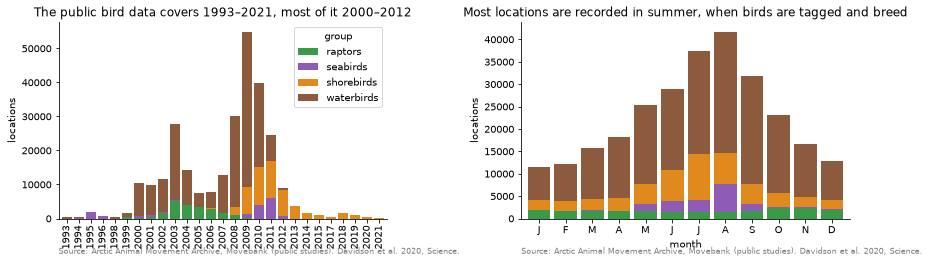

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_year = locs.groupby([locs["t"].dt.year, "group"]).size().unstack(fill_value=0)
by_year.plot.bar(stacked=True, ax=axes[0], color=[GROUP_COLOR[g] for g in by_year.columns], width=0.85)
axes[0].set(title="The public bird data covers 1993–2021, most of it 2000–2012", xlabel="", ylabel="locations")
by_month = locs.groupby([locs["t"].dt.month, "group"]).size().unstack(fill_value=0)
by_month.plot.bar(stacked=True, ax=axes[1], color=[GROUP_COLOR[g] for g in by_month.columns], legend=False, width=0.85)
axes[1].set(title="Most locations are recorded in summer, when birds are tagged and breed", xlabel="month", ylabel="locations")
axes[1].set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"], rotation=0)
for ax in axes:
    source_note(ax, CREDIT)
plt.tight_layout()

### 5.2 Over the latitudes

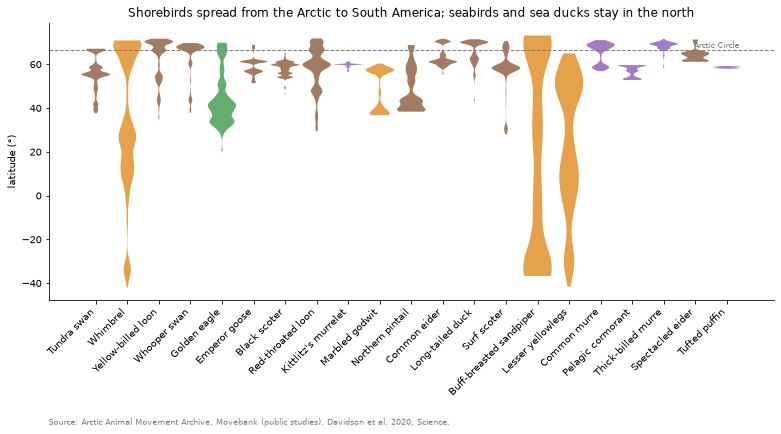

In [10]:
order = volume.index.get_level_values("name")
fig, ax = plt.subplots(figsize=(13, 5))
data = [locs.loc[locs["name"] == n, "lat"] for n in order]
parts = ax.violinplot(data, showextrema=False, widths=0.9)
for body, n in zip(parts["bodies"], order):
    body.set_facecolor(GROUP_COLOR[SPECIES[locs.loc[locs['name'] == n, 'species'].iloc[0]][1]])
    body.set_alpha(0.8)
ax.axhline(66.56, color="gray", linestyle="--", linewidth=1)
ax.annotate("Arctic Circle", (len(order) + 0.4, 66.56), va="bottom", ha="right", fontsize=8, color="gray")
ax.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right")
ax.set(title="Shorebirds spread from the Arctic to South America; seabirds and sea ducks stay in the north",
       ylabel="latitude (°)")
source_note(ax, CREDIT, y=-0.45)

## 6. A year of movement

### 6.1 Where they go

All tracks on a map centred on the North Pole. Each line is one individual.

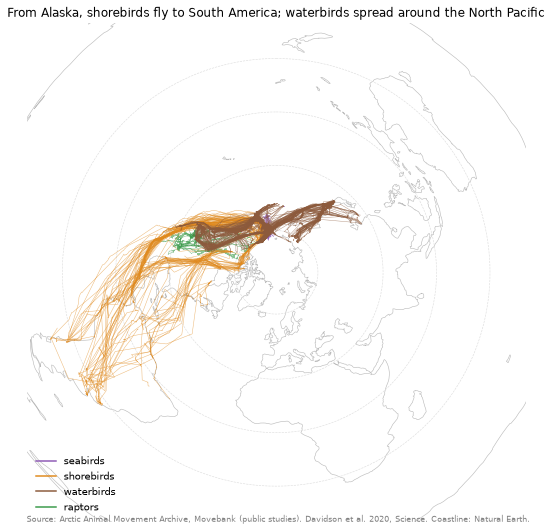

In [11]:
COAST_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/v5.1.2/geojson/ne_110m_coastline.geojson"
coast = json.loads(download("ne_110m_coastline.geojson", COAST_URL).read_text())


def polar(lat, lon):
    """Azimuthal equidistant projection around the North Pole, in degrees from the pole."""
    r, a = 90 - np.asarray(lat), np.radians(np.asarray(lon))
    return r * np.sin(a), -r * np.cos(a)


def draw_base(ax, rmax=140, lat=None, lon=None):
    """Coastlines and parallels; zoom to the given positions if any."""
    data_lat, data_lon = lat, lon
    for f in coast["features"]:
        lon, lat = np.array(f["geometry"]["coordinates"]).T
        ax.plot(*polar(lat, lon), color="#bbbbbb", linewidth=0.6)
    for lat in (66.56, 30, 0, -30):
        th = np.linspace(0, 2 * np.pi, 361)
        ax.plot((90 - lat) * np.sin(th), (90 - lat) * np.cos(th), color="#dddddd", linewidth=0.6, linestyle="--")
    if data_lat is None:
        ax.set(xlim=(-rmax, rmax), ylim=(-rmax, rmax))
    else:  # zoom to the data, as a square with a margin
        x, y = polar(data_lat, data_lon)
        cx, cy = (x.min() + x.max()) / 2, (y.min() + y.max()) / 2
        half = max(x.max() - x.min(), y.max() - y.min()) / 2 + 4
        ax.set(xlim=(cx - half, cx + half), ylim=(cy - half, cy + half))
    ax.set(aspect="equal", xticks=[], yticks=[])
    for s in ax.spines.values():
        s.set_visible(False)


fig, ax = plt.subplots(figsize=(9, 9))
draw_base(ax)
for (group, ind), d in locs.groupby(["group", "individual"]):
    ax.plot(*polar(d["lat"], d["lon"]), color=GROUP_COLOR[group], linewidth=0.5, alpha=0.6)
for g, c in GROUP_COLOR.items():
    ax.plot([], [], color=c, label=g)
ax.legend(loc="lower left", frameon=False)
ax.set_title("From Alaska, shorebirds fly to South America; waterbirds spread around the North Pacific")
source_note(ax, CREDIT + " Coastline: Natural Earth.", y=0.0)

### 6.2 One distance per day

To measure how far a bird travels, we first reduce each individual to **one position per day**: the median latitude and the circular mean longitude of that day's locations. This keeps Argos scatter and different fix rates from inflating the distance: a bird with 20 noisy fixes a day would otherwise look busier than one with a single fix.

In [12]:
def to_daily(table):
    """One position per individual per day, with the km from the day before it."""
    table = table.assign(day=table["t"].dt.floor("D"), cx=np.cos(np.radians(table["lon"])), cy=np.sin(np.radians(table["lon"])))
    days = table.groupby(["group", "name", "individual", "day"]).agg(lat=("lat", "median"), cx=("cx", "mean"), cy=("cy", "mean")).reset_index()
    days["lon"] = np.degrees(np.arctan2(days["cy"], days["cx"]))
    prev = days.groupby("individual")[["lat", "lon"]].shift()
    days["km"] = haversine_km(prev["lat"], prev["lon"], days["lat"], days["lon"]).fillna(0)
    days["doy"] = days["day"].dt.day_of_year
    return days


daily = to_daily(locs)
print(f"{len(daily):,} bird-days")

57,052 bird-days


### 6.3 Season by season on the map

Each species on its own map, zoomed to where it goes. Each dot is one bird on one day, coloured by the month: winter blue, spring green, summer yellow, autumn red. The colours show where the birds are at each time of year and which way they go. Grey lines join each bird's days.

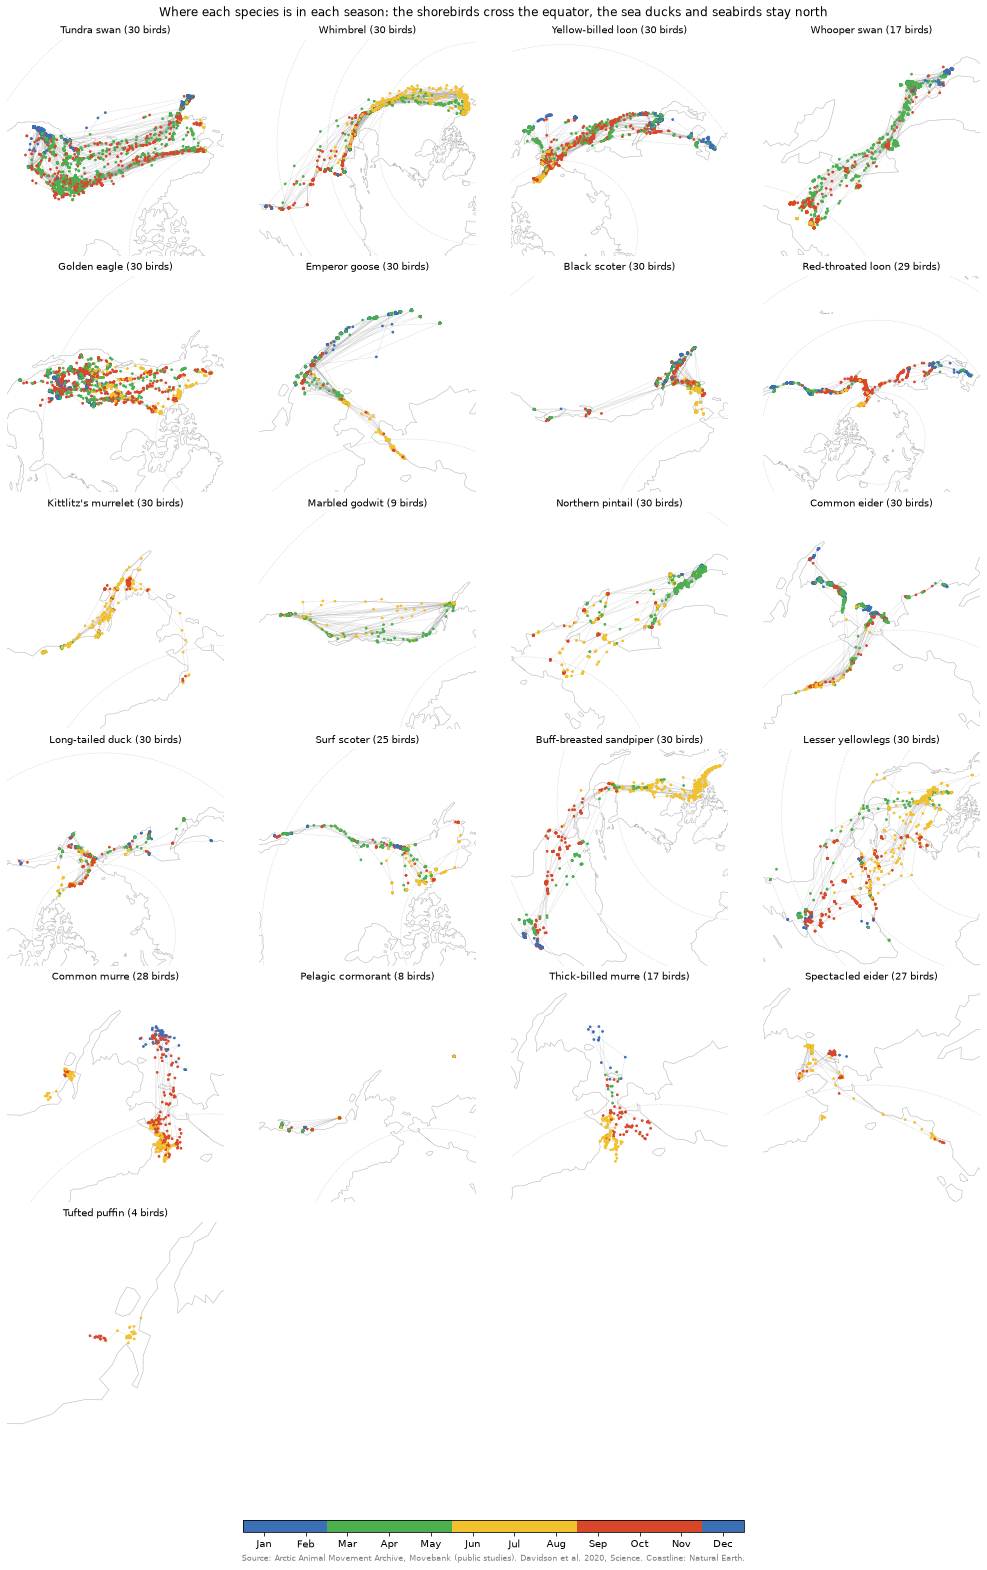

In [13]:
from matplotlib.colors import ListedColormap

SEASON = ListedColormap(["#3b6fb6", "#3b6fb6", "#4caf50", "#4caf50", "#4caf50", "#f2c12e",
                         "#f2c12e", "#f2c12e", "#d9472b", "#d9472b", "#d9472b", "#3b6fb6"])  # Jan..Dec
daily["month"] = daily["day"].dt.month


def season_map(ax, d, title):
    draw_base(ax, lat=d["lat"], lon=d["lon"])
    for _, b in d.groupby("individual"):
        ax.plot(*polar(b["lat"], b["lon"]), color="#999999", linewidth=0.3, alpha=0.5)
    ax.scatter(*polar(d["lat"], d["lon"]), c=d["month"], cmap=SEASON, vmin=0.5, vmax=12.5, s=3, zorder=3)
    ax.set_title(title, fontsize=10)


cols = 4
rows_n = int(np.ceil(len(order) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(14, 3.6 * rows_n), layout="constrained")
for ax, n in zip(axes.flat, order):
    d = daily[daily["name"] == n]
    season_map(ax, d, f"{n} ({d['individual'].nunique()} birds)")
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
sm = plt.cm.ScalarMappable(cmap=SEASON, norm=plt.Normalize(0.5, 12.5))
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", shrink=0.5, aspect=40, ticks=range(1, 13))
cbar.ax.set_xticklabels([m.strftime("%b") for m in pd.date_range("2001-01-01", periods=12, freq="MS")])
fig.suptitle("Where each species is in each season: the shorebirds cross the equator, the sea ducks and seabirds stay north")
cbar.set_label(CREDIT + " Coastline: Natural Earth.", fontsize=8, color="gray")

### 6.4 The yearly rhythm

Latitude through the year, with all years folded into one as in EIC's own scenes. Each dot is one bird on one day.

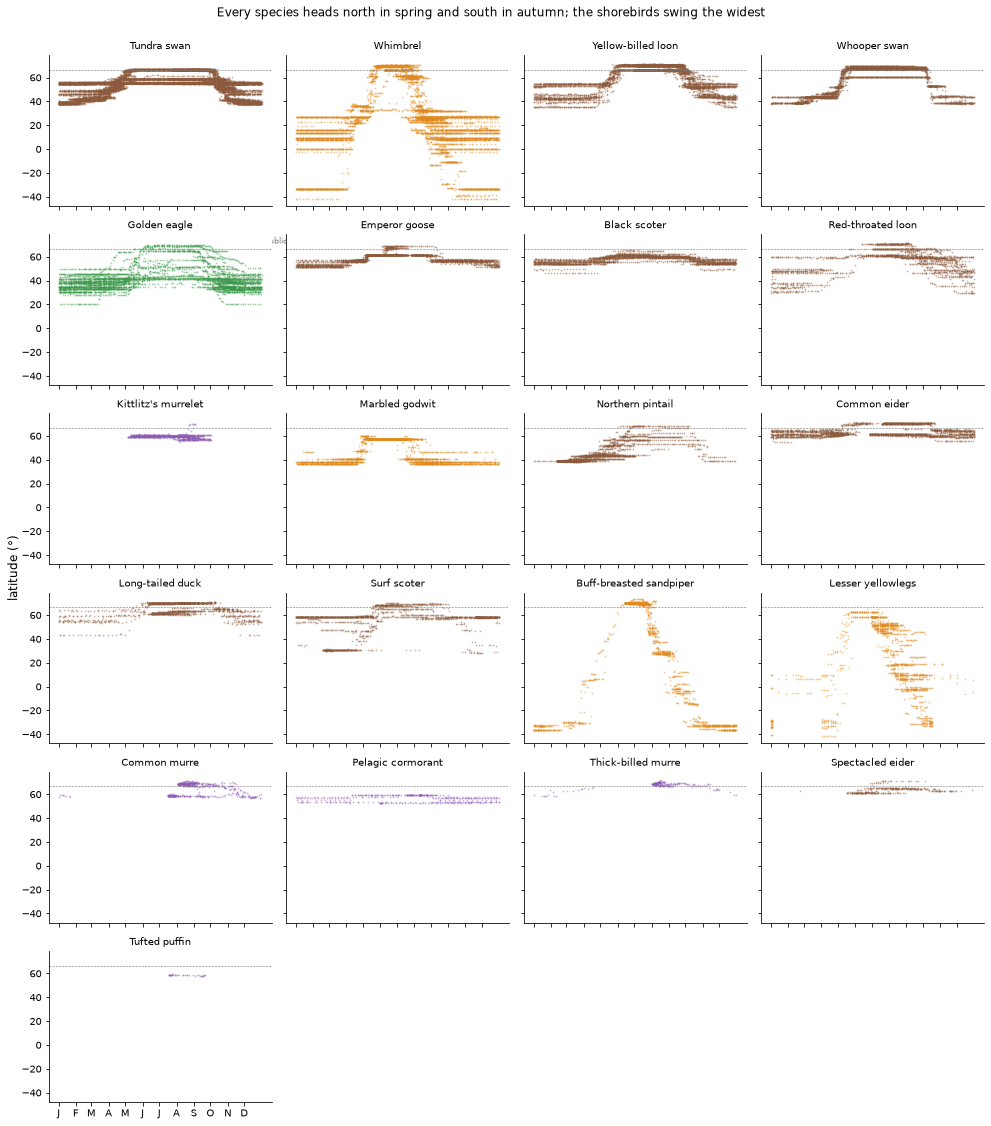

In [14]:
names = list(order)
cols = 4
rows_n = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(14, 2.6 * rows_n), sharex=True, sharey=True)
for ax, n in zip(axes.flat, names):
    d = daily[daily["name"] == n]
    ax.scatter(d["doy"], d["lat"], s=1, color=GROUP_COLOR[d["group"].iloc[0]], alpha=0.3)
    ax.axhline(66.56, color="gray", linestyle="--", linewidth=0.6)
    ax.set_title(n, fontsize=10)
for ax in axes.flat[len(names):]:
    ax.set_visible(False)
months = pd.date_range("2001-01-01", periods=12, freq="MS")
for ax in axes[-1]:
    ax.set_xticks(months.day_of_year, [m.strftime("%b")[0] for m in months])
fig.supylabel("latitude (°)")
fig.suptitle("Every species heads north in spring and south in autumn; the shorebirds swing the widest", y=1.0)
plt.tight_layout()
source_note(axes.flat[0], CREDIT, y=-0.25)

### 6.5 Total distance in one year

For each individual tracked for at least 330 days, we add up its daily distances over its **first 365 days** of tracking. A species' value is the median of its individuals. Species with no individual tracked that long cannot be ranked.

,group,name,individuals,median_km,min_km,max_km
1,shorebirds,Lesser yellowlegs,8,24670.0,15125.0,26127.0
2,shorebirds,Whimbrel,9,20306.0,13280.0,29904.0
3,waterbirds,Yellow-billed loon,19,10289.0,3626.0,15322.0
4,waterbirds,Red-throated loon,4,9699.0,4367.0,14935.0
5,waterbirds,Tundra swan,24,8967.0,1062.0,11758.0
6,waterbirds,Whooper swan,6,8920.0,7769.0,9391.0
7,shorebirds,Marbled godwit,6,8037.0,6942.0,8673.0
8,waterbirds,Long-tailed duck,7,5460.0,3130.0,10462.0
9,raptors,Golden eagle,11,5122.0,1269.0,12601.0
10,waterbirds,Surf scoter,4,5083.0,3221.0,7227.0


Not ranked (no individual tracked for a full year): Buff-breasted sandpiper, Common murre, Kittlitz's murrelet, Spectacled eider, Thick-billed murre, Tufted puffin


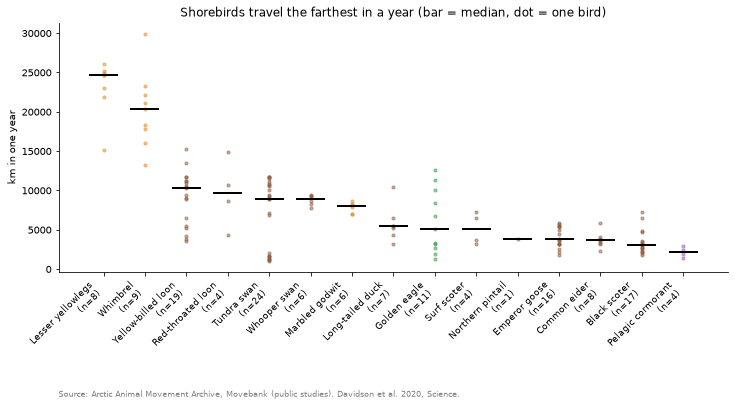

In [15]:
MIN_SPAN_DAYS = 330
start = daily.groupby("individual")["day"].transform("min")
first_year = daily[daily["day"] < start + pd.Timedelta(days=365)]
ind_year = first_year.groupby(["group", "name", "individual"]).agg(
    km=("km", "sum"), span=("day", lambda d: (d.max() - d.min()).days)).reset_index()
full = ind_year[ind_year["span"] >= MIN_SPAN_DAYS]
annual = (full.groupby(["group", "name"])["km"].agg(individuals="size", median_km="median", min_km="min", max_km="max")
          .reset_index().sort_values("median_km", ascending=False).reset_index(drop=True))
annual.index += 1
not_ranked = sorted(set(names) - set(annual["name"]))

fig, ax = plt.subplots(figsize=(12, 4.5))
for i, r in annual.iterrows():
    pts = full.loc[full["name"] == r["name"], "km"]
    ax.scatter(np.full(len(pts), i), pts, s=10, color=GROUP_COLOR[r["group"]], alpha=0.5)
    ax.hlines(r["median_km"], i - 0.35, i + 0.35, color="black", linewidth=2)
ax.set_xticks(annual.index, [f"{n}\n(n={k})" for n, k in zip(annual["name"], annual["individuals"])], rotation=45, ha="right", fontsize=9)
ax.set(ylabel="km in one year", title="Shorebirds travel the farthest in a year (bar = median, dot = one bird)")
source_note(ax, CREDIT, y=-0.5)
display(annual.round(0))
print("Not ranked (no individual tracked for a full year):", ", ".join(not_ranked) or "none")

### 6.6 The top four, month by month

How the year's distance is spread over the months, for the four species that travel the farthest. A bird counts for a month when its tracking covers the whole month, even if some days have no fix (Argos tags often transmit only every few days; the step after a gap still counts). Each month shows the median distance over those birds. These monthly curves are what a track could play.

name,Lesser yellowlegs,Whimbrel,Yellow-billed loon,Red-throated loon
month,,,,
1,126.0,49.0,70.0,85.0
2,0.0,44.0,48.0,59.0
3,0.0,66.0,67.0,125.0
4,3381.0,3054.0,118.0,1258.0
5,6164.0,5030.0,3033.0,1472.0
6,13.0,91.0,475.0,2212.0
7,2823.0,1339.0,53.0,45.0
8,3788.0,5716.0,45.0,315.0
9,1537.0,948.0,1125.0,753.0


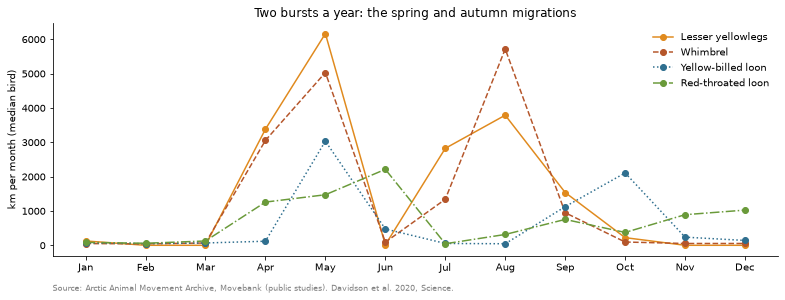

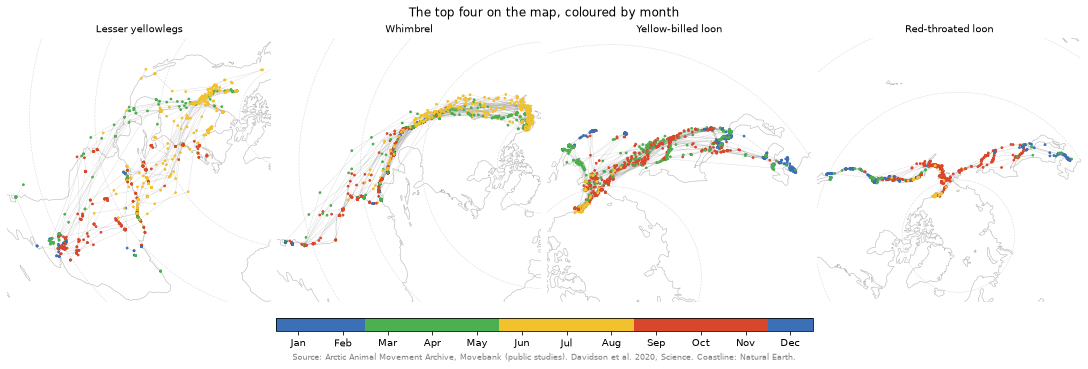

In [16]:
TOP = list(annual["name"].head(4))
top_daily = daily[daily["name"].isin(TOP)]
km_month = top_daily.groupby(["name", "individual", top_daily["day"].dt.to_period("M")])["km"].sum()
covered = []
for (n, ind), d in top_daily.groupby(["name", "individual"]):
    first, last = d["day"].min(), d["day"].max()
    for p in pd.period_range(first, last, freq="M"):
        if p.start_time >= first and p.end_time.floor("D") <= last:
            covered.append((n, ind, p))
monthly_ind = pd.DataFrame(covered, columns=["name", "individual", "day"])
monthly_ind["km"] = [km_month.get(k, 0.0) for k in monthly_ind.itertuples(index=False, name=None)]
monthly_ind["month"] = monthly_ind["day"].dt.month
monthly = monthly_ind.groupby(["name", "month"])["km"].median().unstack(0).reindex(index=range(1, 13), columns=TOP)

TOP_COLOR = dict(zip(TOP, ["#e08a1e", "#b5562b", "#2f6f8f", "#6a9a3a"]))
fig, ax = plt.subplots(figsize=(13, 4.2))
for n, style in zip(TOP, ["-", "--", ":", "-."]):
    ax.plot(monthly.index, monthly[n], marker="o", color=TOP_COLOR[n], linestyle=style, label=n)
ax.set_xticks(range(1, 13), [m.strftime("%b") for m in months])
ax.set(ylabel="km per month (median bird)", title="Two bursts a year: the spring and autumn migrations")
ax.legend(frameon=False)
source_note(ax, CREDIT, y=-0.15)

fig, axes = plt.subplots(1, 4, figsize=(15, 5), layout="constrained")
for ax, n in zip(axes, TOP):
    season_map(ax, daily[daily["name"] == n], n)
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", shrink=0.5, aspect=40, ticks=range(1, 13))
cbar.ax.set_xticklabels([m.strftime("%b") for m in months])
fig.suptitle("The top four on the map, coloured by month")
cbar.set_label(CREDIT + " Coastline: Natural Earth.", fontsize=8, color="gray")
monthly.round(0)

## 7. Summary

| Question | Answer |
| --- | --- |
| What is it? | Locations of tagged Arctic birds from the AAMA in Movebank, the dataset EIC 4877 cites. Each record is one bird at one time. |
| How much? | See section 4: the public bird studies, capped at 30 individuals each. This is a small, bird-only part of the AAMA (269 studies, 15,585 animals as of Nov 2022). |
| Distribution | Years 1993–2021 (most 2000–2012), mostly Alaska-tagged birds (USGS Alaska Science Center); most fixes in summer; latitudes from the high Arctic to South America for shorebirds. |
| What it says | EIC: animals move with the seasons. In the data, every species goes north in spring and south in autumn, and the distance comes in two bursts a year. |
| Top four by distance in a year | Section 6.5. |

**Caveats (ours):**

- Public studies only, and at most 30 individuals each. The ranking describes these birds, not the species as a whole.
- Some species have few individuals tracked for a full year; their median is less certain (see `n` in 6.5).
- Daily positions understate the true flight path (a bird does not fly in straight lines between days), the same way for every species.

## 8. Track candidates

One series per species of the top four: the median distance per bird in each month (section 6.6), plus the daily positions behind it. Section 9 exports the tracks built from them.

In [17]:
cand = []
for n in TOP:
    d = daily[daily["name"] == n]
    cand.append({"species": n, "series": "km per month, median bird", "length": "12 months",
                 "range": f"{monthly[n].min():.0f}–{monthly[n].max():.0f} km", "behind it": f"{len(d):,} bird-days, {d['individual'].nunique()} birds"})
pd.DataFrame(cand)

,species,series,length,range,behind it
0,Lesser yellowlegs,"km per month, median bird",12 months,0–6164 km,"1,383 bird-days, 30 birds"
1,Whimbrel,"km per month, median bird",12 months,44–5716 km,"6,027 bird-days, 30 birds"
2,Yellow-billed loon,"km per month, median bird",12 months,45–3033 km,"5,504 bird-days, 30 birds"
3,Red-throated loon,"km per month, median bird",12 months,45–2212 km,"1,911 bird-days, 29 birds"


## 9. Track export

The four tracks: the **Buff-breasted sandpiper**, two of the top four of section 6.5, the **Whimbrel** and the **Yellow-billed loon**, and the **Northern pintail**.

The Northern pintail takes the place of the Red-throated loon (our choice). Its one bird tracked a whole year in section 6.5 ranks it far below the top four, but its birds, tagged in northern Japan, fly to the tundra of eastern Siberia each summer and back.

The Buff-breasted sandpiper takes the place of the Lesser yellowlegs (our choice). It cannot be ranked in section 6.5, as none of its birds was tracked a whole year, but it flies one of the longest routes in the archive, from Alaska's Arctic coast to the Pampas of Argentina and Uruguay. Its birds are a fixed list of 93 we picked (`BIRDS_OF` below), tagged in Alaska, Texas, Argentina, Uruguay and Brazil; the steps below choose among their bird-years.

A track file holds the daily positions of chosen bird-years of its species (section 6.2): one bird in one calendar year each, named `<bird>/<year>`. The app lays every year over one, as EIC's scenes do, so the birds of different years fly together through one year. The analysis above caps each study at 30 individuals; the tracks are chosen from **every** individual of the four species' studies, downloaded here as `raw/movebank/<study id>_all.json`, cleaned and reduced to days the same way (sections 3.3 and 6.2), as many birds tracked through the winter are past the first 30.

Which bird-years play (ours): up to 30 per species, chosen so the music has rhythm and the flock stays together on the globe. Every bird-year of at least 20 days can play, except one that moved more than 1,000 km while its tag was silent for over 30 days: the app joins a bird's days with straight lines, so a flight hidden in a silence of months would be drawn as a slow, steady glide across the continent (some Lesser yellowlegs of 2020 did this, from Argentina in January to Central America and Texas in April). The criteria below decide which come first.

1. **Stop and go**: the music turns the flock's speed into rhythm, so birds that rest and then fly in bursts sound better than birds that move evenly. We measure this with the burstiness of a bird-year's daily distance, B = (σ − μ) / (σ + μ): near 0 for even movement, near 1 for long rests broken by bursts. The upper half of each species counts as stop and go.
2. **No vanishing**: a bird whose tag falls silent for more than 7 days seems to vanish and reappear on the map.
3. **Together**: the globe follows the flock's centre, so a bird far from the others runs off the edge. Each day's centre is the median latitude and circular mean longitude of the birds; a bird-year's spread is how far from that centre it is on its farthest 10% of days.

The flock is built in this order:

- **Core**: the stop-and-go bird-years with no silence. The most spread is dropped and the centre measured again, until every one stays within 2,500 km (or only 4 are left).
- **Every day covered**: a day with no bird would be silent, so bird-years covering empty days join next, the one covering the most first.
- **Movement all year**: a day on which fewer than 3 birds of the flock move (10 km or more a day) plays thin rhythm. Most tags are put on in summer, so without this the winter and spring would be carried by a few resting birds. Bird-years that move on at least a week of such days join next, the one moving on the most of them first, short ones included. This brings in the birds that move through the winter and start north early.
- **At most 30**: if the flock is now larger, the core gives way, the most spread bird-year first, so the birds that carry the quiet seasons stay.
- **Up to 30**: the rest join one at a time, always the one closest to the flock so far, in this order of preference: stop and go without silence, stop and go with silence, even movers without silence, then the rest. Only when a species runs out of bird-years of 20 days or more do shorter ones make up the number, the longest first.

Daily positions rather than every fix: one position a day is enough at a week a second of playback, and keeps the files small.

In [18]:
# The species the tracks play, in album order, and each one's colour in the graphs.
TRACK_SPECIES = ["Buff-breasted sandpiper", "Whimbrel", "Yellow-billed loon", "Northern pintail"]
TRACK_COLOR = dict(zip(TRACK_SPECIES, ["#e08a1e", "#b5562b", "#2f6f8f", "#6a9a3a"]))
# A species listed here plays only these birds (Movebank local identifiers); the others play any of theirs.
BIRDS_OF = {
    "Buff-breasted sandpiper": [
    "ak_171286", "ak_171288", "ak_171289", "ak_171290", "ak_171291", "ak_171293", "ak_171296", "ak_171297",
    "ak_171300", "ak_172765", "ak_172766", "ak_172767", "ak_172769", "ak_172770", "ak_173474", "ak_173475",
    "ak_173476", "ak_173477", "ak_173478", "ak_175234", "ak_175235", "ak_175237", "ak_175243", "ak_175246",
    "ak_175248", "ar_171287", "ar_171290", "ar_171292", "ar_171294", "ar_171295", "ar_171298", "br_172764",
    "br_172768", "txn_158760", "txn_158763", "txn_158765", "txn_158768", "txn_158769", "txn_158773", "txn_158778",
    "txn_158779", "txn_158780", "txn_158781", "txn_158782", "txn_158785", "txn_158786", "txn_158789", "txs_158754",
    "txs_158755", "txs_158756", "txs_158757", "txs_158761", "txs_158762", "txs_158767", "txs_158770", "txs_158771",
    "txs_158772", "txs_158774", "txs_158776", "txs_162936", "txs_173479", "txs_175185", "txs_175223", "txs_175224",
    "txs_175225", "txs_175226", "txs_175227", "txs_175228", "txs_175229", "txs_175230", "txs_175231", "txs_175232",
    "txs_175233", "txs_175238", "txs_175239", "txs_175240", "txs_175241", "txs_175242", "txs_175245", "txs_175247",
    "txs_176524", "txs_176526", "txs_176529", "txs_176530", "txs_176532", "txs_176533", "txs_176534", "txs_176535",
    "ur_171299", "ur_172760", "ur_172761", "ur_172762", "ur_172763",
    ],
}
TRACKS = Path("../data/arctic_bird/tracks")
TRACKS.mkdir(parents=True, exist_ok=True)
MIN_DAYS = 20
MAX_GAP_DAYS = 7
# A silence this long over which a bird moved this far hides a flight the app would draw as a slow glide.
LONG_SILENCE_DAYS = 30
MAX_SILENT_MOVE_KM = 1000
MAX_SPREAD_KM = 2500
MIN_TRACKS = 4
# A bird flying at least this far a day counts as moving that day.
MOVING_KM_PER_DAY = 10
# A day with fewer birds moving than this plays thin rhythm; a bird-year moving on at least MIN_GAIN_DAYS of them joins.
MIN_MOVERS = 3
MIN_GAIN_DAYS = 7
MAX_TRACKS = 30
YEAR_DAYS = set(range(1, 366))


def slug(name):
    return re.sub(r"[^a-z]+", "_", name.lower()).strip("_")


def burstiness(rate):
    s, m = rate.std(), rate.mean()
    return (s - m) / (s + m) if s + m > 0 else np.nan


# Every individual of the top four's studies, cleaned and reduced to days as above.
TOP_STUDIES = sorted(locs.loc[locs["name"].isin(TRACK_SPECIES), "study_id"].unique())
all_locs = clean(study_locations(TOP_STUDIES, limit=None))
all_locs = all_locs.assign(name=all_locs["species"].map(lambda s: SPECIES[s][0]), group=all_locs["species"].map(lambda s: SPECIES[s][1]))
all_daily = to_daily(all_locs)


def bird_year_days(name):
    """Daily positions of the species, one row per bird-year per day, with km per day since the day before."""
    d = all_daily[all_daily["name"] == name].copy()
    if name in BIRDS_OF:
        d = d[d["individual"].str.split("/", n=1).str[1].isin(BIRDS_OF[name])]
    d["track"] = d["individual"] + "/" + d["day"].dt.year.astype(str)
    d = d.sort_values(["track", "day"])
    d["gap"] = d.groupby("track")["day"].diff().dt.days
    d["rate"] = d["km"] / d["gap"]
    return d


def flock_centre(d):
    """Each day of the year's centre of the bird-years in `d`: median latitude, circular mean longitude."""
    lon_r = np.radians(d["lon"])
    c = d.assign(cx=np.cos(lon_r), cy=np.sin(lon_r)).groupby("doy").agg(clat=("lat", "median"), cx=("cx", "mean"), cy=("cy", "mean"))
    c["clon"] = np.degrees(np.arctan2(c["cy"], c["cx"]))
    return c[["clat", "clon"]]


def spread_km(d, centre=None):
    """Each bird-year's 90th percentile distance from `centre` (by default, that of the bird-years in `d`), over the
    days the centre has; infinite for a bird-year that shares no day with it."""
    d = d.join(flock_centre(d) if centre is None else centre, on="doy", how="inner")
    d["off"] = haversine_km(d["lat"], d["lon"], d["clat"], d["clon"])
    return d.groupby("track")["off"].quantile(0.9)


def choose(name):
    d = bird_year_days(name)
    g = d.groupby("track")
    silent_move = d["km"].where(d["gap"] > LONG_SILENCE_DAYS).groupby(d["track"]).max().fillna(0)
    stats = pd.DataFrame({"days": g.size(), "burstiness": g["rate"].agg(burstiness), "max gap": g["gap"].max(),
                          "silent move km": silent_move, "first": g["doy"].min(), "last": g["doy"].max()})
    pool = stats[(stats["days"] >= MIN_DAYS) & (stats["silent move km"] <= MAX_SILENT_MOVE_KM)].dropna(subset=["burstiness"])
    gliders = stats[(stats["days"] >= MIN_DAYS) & (stats["silent move km"] > MAX_SILENT_MOVE_KM)].index
    # Shorter bird-years, longest first: only to make up the number when the long ones run out.
    short = stats[(stats["days"] < MIN_DAYS) & (stats["days"] >= 2) & (stats["silent move km"] <= MAX_SILENT_MOVE_KM)]
    short = short.sort_values("days", ascending=False, kind="stable")
    bursty = pool[pool["burstiness"] >= pool["burstiness"].median()]
    keep = list(bursty[bursty["max gap"] <= MAX_GAP_DAYS].index)
    while len(keep) > MIN_TRACKS:
        spread = spread_km(d[d["track"].isin(keep)])
        if spread.max() <= MAX_SPREAD_KM:
            break
        keep.remove(spread.idxmax())
    reason = {t: "stop and go, together" for t in keep}

    def covered(tracks):
        return set().union(*(range(stats.at[t, "first"], stats.at[t, "last"] + 1) for t in tracks)) if tracks else set()

    # Days each bird-year moves on: every day of a step of 30 days or less at MOVING_KM_PER_DAY or more.
    steps = d[(d["gap"] <= LONG_SILENCE_DAYS) & (d["rate"] >= MOVING_KM_PER_DAY)]
    moving = {t: set() for t in stats.index}
    for t, doy, gap in zip(steps["track"], steps["doy"], steps["gap"].astype(int)):
        moving[t].update(range(doy - gap + 1, doy + 1))

    for backups, why in ((bursty.index, "fills empty days (silent tag)"), (pool.index, "fills empty days")):
        while True:
            empty = YEAR_DAYS - covered(keep)
            gain = {t: len(empty & covered([t])) for t in backups if t not in keep}
            best = max(gain, key=gain.get, default=None)
            if best is None or gain[best] == 0:
                break
            keep.append(best)
            reason[best] = why

    # Days when fewer than MIN_MOVERS birds of the flock move play thin rhythm: bird-years moving on them join next, the
    # one moving on the most such days first, from every bird-year that can play, the short ones too.
    def thin_days(tracks):
        movers = pd.Series(0, index=sorted(YEAR_DAYS))
        for t in tracks:
            movers[list(moving[t] & YEAR_DAYS)] += 1
        return set(movers.index[movers < MIN_MOVERS])

    added = 0
    while added < MAX_TRACKS - MIN_TRACKS:
        thin = thin_days(keep)
        gain = {t: len(thin & moving[t]) for t in list(pool.index) + list(short.index) if t not in keep}
        best = max(gain, key=gain.get, default=None)
        if best is None or gain[best] < MIN_GAIN_DAYS:
            break
        keep.append(best)
        reason[best] = "moves when few others do"
        added += 1

    # Over MAX_TRACKS: the core gives way, the most spread first, so the birds that carry the quiet seasons stay.
    while len(keep) > MAX_TRACKS:
        core = [t for t in keep if reason[t] == "stop and go, together"]
        spread = spread_km(d[d["track"].isin(keep)]).reindex(core)
        keep.remove(spread.idxmax())

    # Up to MAX_TRACKS: the rest join in order of preference, each time the one closest to the flock so far.
    preference = [
        (bursty.index[bursty["max gap"] <= MAX_GAP_DAYS], "stop and go, beyond the spread"),
        (bursty.index, "stop and go, silent tag"),
        (pool.index[pool["max gap"] <= MAX_GAP_DAYS], "moves evenly"),
        (pool.index, "moves evenly, silent tag"),
        (short.index, "short, to make up the number"),
    ]
    for group, why in preference:
        while len(keep) < MAX_TRACKS:
            options = [t for t in group if t not in keep]
            if not options:
                break
            spread = spread_km(d[d["track"].isin(options)], flock_centre(d[d["track"].isin(keep)])).reindex(options, fill_value=np.inf)
            # Ties (short ones that share no day with the flock) go to the longest, as `group` is ordered.
            best = spread.index[np.argmin(spread.to_numpy())]
            keep.append(best)
            reason[best] = why
    chosen = stats.loc[keep].assign(reason=[reason[t] for t in keep], spread_km=spread_km(d[d["track"].isin(keep)]).reindex(keep))
    rows = d[d["track"].isin(keep)].rename(columns={"day": "date", "lat": "lat_deg", "lon": "lon_deg"})
    return rows[["date", "track", "lat_deg", "lon_deg"]], chosen, len(pool), list(gliders)


# Why each bird-year was chosen, in the order the flock is built.
REASONS = ["stop and go, together", "fills empty days (silent tag)", "fills empty days", "moves when few others do",
           "stop and go, beyond the spread",
           "stop and go, silent tag", "moves evenly", "moves evenly, silent tag", "short, to make up the number"]
tracks, chosen = {}, {}
summary = []
for n in TRACK_SPECIES:
    tracks[n], chosen[n], pooled, gliders = choose(n)
    c = chosen[n]
    summary.append({"species": n, "left out: moved while silent": len(gliders), "bird-years that can play": pooled, "chosen": len(c),
                    **c["reason"].value_counts().reindex(REASONS, fill_value=0).to_dict(),
                    "burstiness (median chosen)": round(c["burstiness"].median(), 2),
                    "spread km (largest)": round(c["spread_km"].max()),
                    "empty days": len(YEAR_DAYS - set().union(*(range(f, l + 1) for f, l in zip(c["first"], c["last"]))))})
pd.DataFrame(summary).set_index("species").T

species,Buff-breasted sandpiper,Whimbrel,Yellow-billed loon,Northern pintail
left out: moved while silent,0.00,0.00,6.00,0.00
bird-years that can play,74.00,56.00,189.00,119.00
chosen,30.00,30.00,30.00,30.00
"stop and go, together",11.00,15.00,14.00,21.00
fills empty days (silent tag),0.00,0.00,0.00,0.00
fills empty days,1.00,0.00,0.00,1.00
moves when few others do,18.00,15.00,16.00,8.00
"stop and go, beyond the spread",0.00,0.00,0.00,0.00
"stop and go, silent tag",0.00,0.00,0.00,0.00
moves evenly,0.00,0.00,0.00,0.00


Every day of the year should have birds on the map, or the music would fall silent there. The count of bird-years on the map, day by day:

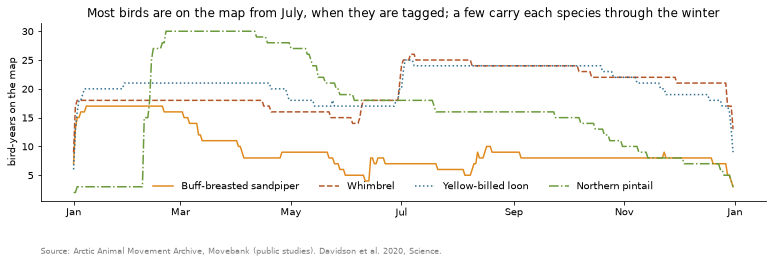

In [19]:
fig, ax = plt.subplots(figsize=(13, 3.2))
for n, style in zip(TRACK_SPECIES, ["-", "--", ":", "-."]):
    t = tracks[n]
    span = t.groupby("track")["date"].agg(["min", "max"])
    doy = np.arange(1, 366)
    first, last = span["min"].dt.day_of_year.to_numpy(), span["max"].dt.day_of_year.to_numpy()
    on_map = ((doy[:, None] >= first) & (doy[:, None] <= last)).sum(axis=1)
    ax.plot(pd.date_range("2001-01-01", periods=365), on_map, color=TRACK_COLOR[n], linestyle=style, label=n)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
ax.set(ylabel="bird-years on the map", title="Most birds are on the map from July, when they are tagged; a few carry each species through the winter")
ax.legend(frameon=False, ncol=4)
source_note(ax, CREDIT, y=-0.3)

Export: one CSV per track and `tracks.json` (see [data-guide.md](../docs/data-guide.md)).

In [20]:
STUDY_OF = locs.groupby("name")["study_id"].first()
MESSAGE = plain(page["media_groups"][0].get("caption"))
for old in TRACKS.glob("*.csv"):  # tracks/ is written only here
    old.unlink()
entries = []
for n, t in tracks.items():
    file = f"{slug(n)}.csv"
    t.round({"lat_deg": 3, "lon_deg": 3}).to_csv(TRACKS / file, index=False, date_format="%Y-%m-%d")
    study = int(STUDY_OF[n])
    entries.append({
        "file": file,
        "title": f"{n}, one year",
        "species": n,
        "message": MESSAGE,
        "svsId": SVS_ID,
        "svsUrl": f"https://svs.gsfc.nasa.gov/{SVS_ID}/",
        "source": f"Arctic Animal Movement Archive (AAMA), Movebank study {study}: {public[study]['name']}",
        "sourceUrl": AAMA_URL,
        "downloadUrl": f"{MOVEBANK}?entity_type=event&study_id={study}",
        "credit": "Movebank / Arctic Animal Movement Archive (Davidson et al. 2020)",
        "units": {"track": "bird / calendar year", "lat_deg": "degrees north", "lon_deg": "degrees east"},
        "timeRange": [t["date"].min().strftime("%Y-%m-%d"), t["date"].max().strftime("%Y-%m-%d")],
    })
    if n in set(annual["name"]):
        entries[-1]["annualKmMedian"] = round(float(annual.set_index("name").loc[n, "median_km"]))
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")
assert sorted(p.name for p in TRACKS.glob("*.csv")) == sorted(e["file"] for e in entries)
pd.DataFrame([{"file": e["file"], "KB": round((TRACKS / e["file"]).stat().st_size / 1024)} for e in entries])

,file,KB
0,buff_breasted_sandpiper.csv,67
1,whimbrel.csv,172
2,yellow_billed_loon.csv,193
3,northern_pintail.csv,187
